# Results section 3, and Figure 3

## Setup

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

warnings.filterwarnings("ignore")
%matplotlib inline

# the package root is the first folder at or above this one that holds Data/
def _root(start=None):
    here = Path(__file__).resolve() if "__file__" in globals() else Path.cwd().resolve()
    for c in (here, *here.parents):
        if (c / "Data" / "conversation_turns.csv").exists():
            return c
    raise RuntimeError(f"cannot find the package root (no Data/conversation_turns.csv at or above {here})")

ROOT   = _root()
CLEAN  = ROOT / "Data"
FIGDIR = ROOT / "Code" / "_output" / "figures"; FIGDIR.mkdir(parents=True, exist_ok=True)
RESDIR = ROOT / "Code" / "_output" / "results"; RESDIR.mkdir(parents=True, exist_ok=True)

COL = {"partner": "#00798C", "own": "#D1495B", "solo": "#2B4C7E",
       "grey": "#6E6E6E", "light": "#BFBFBF", "third": "#E8871A"}
SINGLE, DOUBLE = 3.46, 7.09

mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 6.5, "axes.labelsize": 7, "axes.titlesize": 7.5,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "lines.linewidth": 1.3, "lines.markersize": 3.5,
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02, "pdf.fonttype": 42, "ps.fonttype": 42,
})

def panel(ax, letter, title=None, dx=None, dy=None):
    # panel letter at the axes' left edge, in figure coordinates
    fg = ax.figure; bb = ax.get_position()
    fg.text(bb.x0, bb.y1 + .014, letter, fontsize=8, fontweight="bold",
            va="bottom", ha="left")
    if title:
        # title on the letter's baseline, 0.135 in to its right
        fg.text(bb.x0 + 0.135 / fg.get_size_inches()[0], bb.y1 + .014, title,
                fontsize=6.8, va="bottom", ha="left", color="#2A2A2A")

def close_corner(fig):
    # move each lower axis limit to the first tick when no data lie below it
    for ax in fig.axes:
        if not ax.axison:
            continue
        for get_lim, set_lim, ticks_of, data_lo in (
                (ax.get_xlim, ax.set_xlim, ax.get_xticks, lambda: ax.dataLim.x0),
                (ax.get_ylim, ax.set_ylim, ax.get_yticks, lambda: ax.dataLim.y0)):
            lo, hi = get_lim()
            if hi <= lo:
                continue
            inside = [t for t in ticks_of() if lo <= t <= hi]
            if not inside:
                continue
            first = min(inside)
            if first <= lo:
                continue
            d = data_lo()
            # keep a small gap between the axis and the nearest data point
            if d != d or d < first + (hi - lo) * 0.03:
                continue
            set_lim(first, hi)
        ax.spines["left"].set_bounds(*ax.get_ylim())
        ax.spines["bottom"].set_bounds(*ax.get_xlim())

def save(fig, name):
    fig.savefig(FIGDIR / f"{name}.pdf")
    fig.savefig(FIGDIR / f"{name}.tif", dpi=300, pil_kwargs={"compression": "tiff_lzw"})
    print(f"wrote {name}.pdf and .tif to Code/_output/figures/")

### Helper functions

In [2]:
def raincloud(ax, groups, colors, labels=None, width=.32, jitter=.075, ms=2.6,
              seed=0, alpha_pts=.40, show_n=False):
    # half a density on the right, the raw points on the left, a quartile bar between them
    rg = np.random.default_rng(seed)
    for i, (vals, c) in enumerate(zip(groups, colors)):
        v = np.asarray(vals, float); v = v[np.isfinite(v)]
        if len(v) > 4 and v.std() > 0:
            kde = stats.gaussian_kde(v)
            grid = np.linspace(v.min() - .05 * np.ptp(v), v.max() + .05 * np.ptp(v), 200)
            d = kde(grid); d = d / d.max() * width
            ax.fill_betweenx(grid, i + .07, i + .07 + d, color=c, alpha=.28, lw=0, zorder=2)
            ax.plot(i + .07 + d, grid, color=c, lw=.7, zorder=3)
        x = i - .13 - np.abs(rg.normal(0, jitter, len(v)))
        ax.scatter(x, v, s=ms, color=c, alpha=alpha_pts, edgecolors="none", zorder=2)
        q1, med, q3 = np.percentile(v, [25, 50, 75])
        ax.plot([i, i], [q1, q3], color=c, lw=3.2, solid_capstyle="butt", zorder=5)
        ax.plot([i], [med], "o", color="white", ms=2.8, mec=c, mew=.7, zorder=6)
        if show_n:
            ax.text(i, ax.get_ylim()[0], f"n = {len(v)}", ha="center", va="bottom",
                    fontsize=5.4, color=COL["grey"])
    ax.set_xticks(range(len(groups)))
    if labels:
        ax.set_xticklabels(labels)
    ax.set_xlim(-.55, len(groups) - .45)

from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

def glmm(formula, data, crossed, label=""):
    # crossed random intercepts, variational Bayes
    vc = {g: f"0 + C({g})" for g in crossed}
    # seed the variational fit
    np.random.seed(2026)
    m = BinomialBayesMixedGLM.from_formula(formula, vc, data).fit_vb()
    if label:
        print(f"  {label}")
    print(f"    {'term':<18}{'b':>9}{'SD':>8}{'95% CrI':>21}{'odds':>8}")
    for i, nm in enumerate(m.model.exog_names):
        lo, hi = m.fe_mean[i] - 1.96 * m.fe_sd[i], m.fe_mean[i] + 1.96 * m.fe_sd[i]
        print(f"    {nm:<18}{m.fe_mean[i]:>9.3f}{m.fe_sd[i]:>8.3f}"
              f"   [{lo:+.3f}, {hi:+.3f}]{np.exp(m.fe_mean[i]):>8.2f}")
    print("    random intercepts (SD, logit scale): "
          + "  ".join(f"{n} {np.exp(v):.2f}" for n, v in zip(m.model.vcp_names, m.vcp_mean)))
    return m

def robust_logit(formula, data, cluster):
    return smf.logit(formula, data=data).fit(disp=0, cov_type="cluster",
                                             cov_kwds={"groups": data[cluster]})

def paired_effect(x, y, unit_label, names=("first", "second")):
    d = np.asarray(y) - np.asarray(x)
    n = len(d); m, sd = d.mean(), d.std(ddof=1)
    se = sd / np.sqrt(n)
    tc = stats.t.ppf(0.975, n - 1)
    t = stats.ttest_rel(y, x)
    print(f"    {names[1]} - {names[0]} = {m:+.3f}   95% CI "
          f"[{m - tc*se:+.3f}, {m + tc*se:+.3f}]   "
          f"t({n-1}) = {t.statistic:+.2f}, p = {t.pvalue:.1e}")
    print(f"    Cohen's dz = {m / sd:+.2f}   ({unit_label}, n = {n})")
    return m, m / sd

## 1 · Decision points in individual and collaborative recall

In [3]:
RECALL = pd.read_csv(CLEAN / "individual_recall.csv")

# recall streams are coded like transcripts: intrusions carry no category and end a run
def _streams(phase):
    d = RECALL[RECALL.phase == phase].sort_values(["participant", "output_position"])
    out = {}
    for p, g in d.groupby("participant"):
        out[str(p)] = [(int(i) if k == "studied" else None,
                        None if k == "other" else int(l))
                       for i, k, l in zip(g.item_id, g.kind, g.list)]
    return out

SOLO_SEQ = _streams("pre")
OWN_IDS = {}
for p, v in SOLO_SEQ.items():
    OWN_IDS[p] = {}
    for i, c in v:
        if i is not None:
            OWN_IDS[p].setdefault(c, set()).add(i)

STREAM = pd.read_pickle(RESDIR / "stream.pkl")

In [4]:
def patch_blocks(cats, kinds=None):
    blocks, cur = [], []
    for i, c in enumerate(cats):
        if c is None:
            if cur:
                blocks.append(cur); cur = []
            continue
        if cur and cats[cur[-1]] == c:
            cur.append(i)
        else:
            if cur:
                blocks.append(cur)
            cur = [i]
    if cur:
        blocks.append(cur)
    return blocks

PERSON_NET = {}
for _, r in STREAM.iterrows():
    for _lt, _p in r.pid.items():
        PERSON_NET[str(_p)] = str(r.network)

rows = []
for p, sq in SOLO_SEQ.items():                       # alone
    cats = [c for _, c in sq]; ids = [i for i, _ in sq]
    for b in patch_blocks(cats):
        c = cats[b[0]]
        for k in range(1, len(b) + 1):
            last = b[k - 1]
            if last == len(cats) - 1:                # nothing follows the last word
                continue
            eaten = {ids[t] for t in range(last + 1)
                     if cats[t] == c and ids[t] is not None}
            rows.append(dict(who="alone", person=p, category=str(c),
                             network=PERSON_NET.get(p, "?"), depth=k,
                             tray=len(OWN_IDS[p].get(c, set()) - eaten),
                             continues=int(len(b) > k)))
for _, r in STREAM.iterrows():                       # talking
    cats, spk, pid, wid = r.cats, r.speakers, r.pid, r.words
    for b in patch_blocks(cats, r.kinds):
        cat = cats[b[0]]
        for k in range(1, len(b) + 1):
            last = b[k - 1]; cur_sp = spk[last]
            # censor the last word and turns followed by the same participant
            if last == len(cats) - 1:
                continue
            nxt = spk[last + 1]
            if nxt == cur_sp:
                continue
            me = str(pid[nxt]); mine = OWN_IDS.get(me, {}).get(cat, set())
            eaten = {wid[t] for t in range(last + 1) if cats[t] == cat}
            rows.append(dict(who="talking", person=me, category=str(cat),
                             network=str(r.network), depth=k, nth=int(r.nth[nxt]),
                             tray=len(mine - eaten), continues=int(len(b) > k)))

MATCH = pd.DataFrame(rows)
MATCH["j"] = MATCH.tray.clip(upper=5)
MATCH["jf"] = MATCH.j.astype(str)
MATCH["first"] = (MATCH.depth == 1).astype(int)

## 2 · Continuation at first and later handovers

In [5]:
# pooled continuation, collaborative relative to individual recall
for lab, sel in [("first handover", MATCH["first"] == 1), ("later handovers", MATCH["first"] == 0)]:
    a = MATCH[(MATCH.who == "alone") & sel].continues.mean()
    t = MATCH[(MATCH.who == "talking") & sel].continues.mean()
    print(f"  {lab:<17} alone {a:.3f}   talking {t:.3f}   ratio {t/a:.0%}")

# per position: paired t test, one value per participant with data in both settings
print("\n  paired t test by position, one value per participant")
for _k in (1, 2, 3, 4):
    _x = MATCH[(MATCH.depth == _k)].groupby(["person", "who"]).continues.mean().unstack()
    _x = _x.dropna(subset=["alone", "talking"])
    _dd = _x.talking - _x.alone
    _tt = stats.ttest_rel(_x.talking, _x.alone)
    print(f"    position {_k}: alone {_x.alone.mean():.3f}, collaborative {_x.talking.mean():.3f}, "
          f"diff {_dd.mean():+.3f}   t({len(_x) - 1}) = {_tt.statistic:+.2f}, "
          f"p = {_tt.pvalue:.1e}, dz = {_dd.mean() / _dd.std(ddof=1):+.2f}   n = {len(_x)}")

  first handover    alone 0.514   talking 0.211   ratio 41%
  later handovers   alone 0.555   talking 0.537   ratio 97%

  paired t test by position, one value per participant
    position 1: alone 0.540, collaborative 0.233, diff -0.307   t(169) = -20.02, p = 1.8e-46, dz = -1.54   n = 170
    position 2: alone 0.589, collaborative 0.561, diff -0.028   t(169) = -1.22, p = 2.3e-01, dz = -0.09   n = 170
    position 3: alone 0.510, collaborative 0.481, diff -0.029   t(153) = -0.87, p = 3.8e-01, dz = -0.07   n = 154
    position 4: alone 0.542, collaborative 0.537, diff -0.005   t(112) = -0.10, p = 9.2e-01, dz = -0.01   n = 113


### 2.1 · Setting x transition model (Supplementary Note 1)

In [6]:
MFIT = glmm("continues ~ C(who, Treatment('alone'))*first + C(jf)", MATCH,
            ["person", "category"],
            "random intercepts: person, category")

  random intercepts: person, category
    term                      b      SD              95% CrI    odds
    Intercept            -1.572   0.021   [-1.613, -1.531]    0.21
    C(who, Treatment('alone'))[T.talking]   -0.133   0.027   [-0.186, -0.080]    0.88
    C(jf)[T.1]            1.705   0.042   [+1.624, +1.787]    5.50
    C(jf)[T.2]            2.265   0.045   [+2.176, +2.353]    9.63
    C(jf)[T.3]            2.660   0.053   [+2.556, +2.763]   14.29
    C(jf)[T.4]            2.709   0.062   [+2.587, +2.831]   15.01
    C(jf)[T.5]            2.803   0.066   [+2.673, +2.933]   16.50
    first                -0.018   0.028   [-0.073, +0.037]    0.98
    C(who, Treatment('alone'))[T.talking]:first   -1.404   0.035   [-1.472, -1.336]    0.25
    random intercepts (SD, logit scale): person 0.60  category 0.29


In [7]:
print("logit, SEs clustered on person")
mc = robust_logit("continues ~ C(who, Treatment('alone'))*first + C(jf)", MATCH, "person")
INT_NAME = "C(who, Treatment('alone'))[T.talking]:first"
print(f"    interaction {mc.params[INT_NAME]:+.3f}   SE {mc.bse[INT_NAME]:.3f}   "
      f"p = {mc.pvalues[INT_NAME]:.1e}")

nets = sorted(set(MATCH.network) - {"?"})
rng = np.random.default_rng(11); boot = []
for _ in range(2000):
    pick = rng.choice(nets, len(nets), replace=True)
    d = pd.concat([MATCH[MATCH.network == nn].assign(_b=f"{nn}_{ii}")
                   for ii, nn in enumerate(pick)])
    try:
        mb = smf.logit("continues ~ C(who, Treatment('alone'))*first + C(jf)", d).fit(disp=0)
        boot.append(mb.params[INT_NAME])
    except Exception:
        pass
boot = np.array(boot)
print("network bootstrap")
print(f"    interaction {boot.mean():+.3f}   95% CI [{np.percentile(boot, 2.5):+.3f}, "
      f"{np.percentile(boot, 97.5):+.3f}]")

logit, SEs clustered on person
    interaction -1.285   SE 0.088   p = 1.1e-48
network bootstrap
    interaction -1.287   95% CI [-1.462, -1.110]


### 2.2 · Per participant (Supplementary Note 5.2)

In [8]:
PP = (MATCH.groupby(["person", "who", "first"]).continues
      .agg(["size", "mean"]).reset_index())
PP = PP[PP["size"] >= 5]
w = PP.pivot_table(index="person", columns=["who", "first"], values="mean")
w.columns = [f"{a}_{b}" for a, b in w.columns]
need = ["alone_1", "alone_0", "talking_1", "talking_0"]
w = w.dropna(subset=need)
print(f"    {len(w)} people with at least 5 decision points in all four cells")
print("    at the first handover")
paired_effect(w.alone_1, w.talking_1, "per person", ("alone", "talking"))
print("    at later handovers")
paired_effect(w.alone_0, w.talking_0, "per person", ("alone", "talking"))
print("    the difference of the two gaps")
paired_effect(w.talking_1 - w.alone_1, w.talking_0 - w.alone_0, "per person",
              ("gap at first", "gap later"))
_gap1 = w.talking_1 - w.alone_1
print(f"    first handover, lower in conversation: {int((_gap1 < 0).sum())} of {len(w)}")

    155 people with at least 5 decision points in all four cells
    at the first handover
    talking - alone = -0.313   95% CI [-0.345, -0.282]   t(154) = -19.68, p = 6.9e-44
    Cohen's dz = -1.58   (per person, n = 155)
    at later handovers
    talking - alone = +0.005   95% CI [-0.022, +0.032]   t(154) = +0.36, p = 7.2e-01
    Cohen's dz = +0.03   (per person, n = 155)
    the difference of the two gaps
    gap later - gap at first = +0.318   95% CI [+0.280, +0.357]   t(154) = +16.44, p = 1.0e-35
    Cohen's dz = +1.32   (per person, n = 155)
    first handover, lower in conversation: 150 of 155


### 2.3 · Continuation in each conversation (Supplementary Note 5.1)

In [9]:
# per-participant rates; the individual-recall baseline (nth = 0) is shared by all three conversations
(RESDIR / "supp").mkdir(exist_ok=True)
_rows = []
_al = MATCH[MATCH.who == "alone"]
for _f in (1, 0):
    _pp = _al[_al["first"] == _f].groupby("person").continues.mean()
    _rows.append(dict(nth=0, first=_f, per_person=_pp.mean(), per_sd=_pp.std(ddof=1),
                      n_people=len(_pp)))
for _k in (1, 2, 3):
    _d = MATCH[(MATCH.who == "talking") & (MATCH.nth == _k)]
    for _f in (1, 0):
        _pp = _d[_d["first"] == _f].groupby("person").continues.mean()
        _rows.append(dict(nth=_k, first=_f, per_person=_pp.mean(), per_sd=_pp.std(ddof=1),
                          n_people=len(_pp)))
pd.DataFrame(_rows).to_csv(RESDIR / "supp" / "s_bynth_cost.csv", index=False)
print(pd.DataFrame(_rows).round(3).to_string(index=False))

 nth  first  per_person  per_sd  n_people
   0      1       0.540   0.192       170
   0      0       0.493   0.175       170
   1      1       0.245   0.232       165
   1      0       0.499   0.314       157
   2      1       0.223   0.179       164
   2      0       0.491   0.282       161
   3      1       0.256   0.220       170
   3      0       0.500   0.279       166


### 2.4 · Interaction with the store

In [10]:
# setting x transition, and its interaction with the store
MATCH["talking"] = (MATCH.who == "talking").astype(int)
MATCH["z_tray"]  = (MATCH.tray - MATCH.tray.mean()) / MATCH.tray.std()
m3 = smf.logit("continues ~ talking * first * z_tray", MATCH).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": MATCH.person})
k = "talking:first:z_tray"
b, se, pv = m3.params[k], m3.bse[k], m3.pvalues[k]
print(f"  setting x transition x store (z)  b = {b:+.3f}  SE {se:.3f}  "
      f"95% CI [{b-1.96*se:+.3f}, {b+1.96*se:+.3f}]  p = {pv:.3f}")

  setting x transition x store (z)  b = +0.080  SE 0.115  95% CI [-0.146, +0.306]  p = 0.486


## 3 · Figure 3

In [11]:
rgb = np.random.default_rng(31)

def binned(df, col, y, cap=4, cluster="person", nboot=2000):
    # bin means with a bootstrap over the clustering unit (per-participant means when cluster="person")
    out = []
    d = df.assign(b=df[col].clip(upper=cap))
    units = d[cluster].unique()
    for k in sorted(d.b.unique()):
        sub = d[d.b == k]
        if cluster == "person":
            pm = sub.groupby(cluster)[y].mean().values
            draws = [pm[rgb.integers(0, len(pm), len(pm))].mean() for _ in range(nboot)]
            out.append((k, pm.mean(), np.percentile(draws, 2.5),
                        np.percentile(draws, 97.5), len(sub)))
            continue
        # per-cluster sums and counts
        agg = sub.groupby(cluster)[y].agg(["sum", "size"]).reindex(units, fill_value=0)
        S_, N_ = agg["sum"].values, agg["size"].values
        draws = []
        for _ in range(nboot):
            ix = rgb.integers(0, len(units), len(units))
            if N_[ix].sum():
                draws.append(S_[ix].sum() / N_[ix].sum())
        out.append((k, sub[y].mean(), np.percentile(draws, 2.5),
                    np.percentile(draws, 97.5), len(sub)))
    return pd.DataFrame(out, columns=["b", "m", "lo", "hi", "n"])

wrote Figure_3.pdf and .tif to Code/_output/figures/


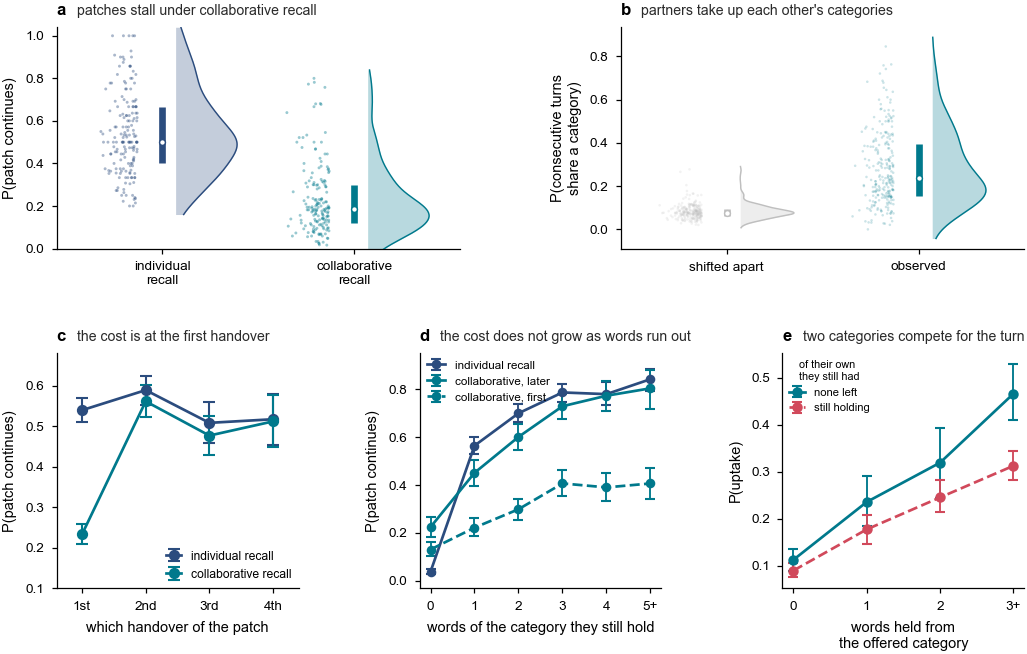

In [12]:
# panels a and b are computed in results2_collaborative_patches.ipynb and read back
PC = pd.read_csv(RESDIR / "merged" / "f3_patch_continues.csv")
CO = pd.read_csv(RESDIR / "merged" / "f3_coincidence.csv")
for _d, _need, _who in ((PC, ["alone", "talking"], "f3_patch_continues.csv"),
                        (CO, ["adj", "adj_shift"], "f3_coincidence.csv")):
    _miss = [c for c in _need if c not in _d.columns]
    if _miss:
        raise RuntimeError(f"results/merged/{_who} is stale or absent ({_miss} missing). "
                           "Run results2_collaborative_patches.ipynb first, then this notebook.")

fig = plt.figure(figsize=(DOUBLE, 4.45))
outer = fig.add_gridspec(2, 1, height_ratios=[1.00, 1.06], hspace=.46,
                         left=.075, right=.985, top=.945, bottom=.105)
g_top = outer[0].subgridspec(1, 2, wspace=.40)
g_bot = outer[1].subgridspec(1, 3, wspace=.50)
ALONE, TALK = COL["solo"], COL["partner"]

# ---------- a - patch continuation by setting ----------
a_ = fig.add_subplot(g_top[0, 0])
raincloud(a_, [PC.alone.values, PC.talking.values], [ALONE, TALK],
          ["individual\nrecall", "collaborative\nrecall"], seed=9, ms=2.0)
a_.set_ylabel("P(patch continues)"); a_.set_ylim(0, 1.04)
panel(a_, "a", "patches stall under collaborative recall")

# ---------- b - shared category in consecutive turns ----------
b_ = fig.add_subplot(g_top[0, 1])
raincloud(b_, [CO.adj_shift.values, CO.adj.values], [COL["light"], TALK],
          ["shifted apart", "observed"], seed=14, ms=1.5, alpha_pts=.20, width=.28)
b_.set_ylabel("P(consecutive turns\nshare a category)")
panel(b_, "b", "partners take up each other's categories")

# ---------- c - by handover position ----------
c_ = fig.add_subplot(g_bot[0, 0])
for who, cc, lab in [("alone", ALONE, "individual recall"), ("talking", TALK, "collaborative recall")]:
    d = MATCH[(MATCH.who == who) & (MATCH.depth <= 4)]
    g = binned(d, "depth", "continues", cap=4, cluster="person")
    c_.errorbar(g.b, g.m, yerr=[g.m - g.lo, g.hi - g.m], fmt="o-", color=cc,
                ms=4.4, capsize=2.8, elinewidth=1.0, label=lab, zorder=4)
c_.set_xticks([1, 2, 3, 4]); c_.set_xticklabels(["1st", "2nd", "3rd", "4th"])
c_.set_xlabel("which handover of the patch")
c_.set_ylabel("P(patch continues)")
c_.set_ylim(.1, .68); c_.set_xlim(.6, 4.4)
c_.legend(loc="lower right", fontsize=5.8, handlelength=1.2, borderaxespad=.2)
panel(c_, "c", "the cost is at the first handover")

# ---------- d - by store size ----------
d_ = fig.add_subplot(g_bot[0, 1])
for sel, cc, ls, lab in [
        (MATCH.who == "alone", ALONE, "-", "individual recall"),
        ((MATCH.who == "talking") & (MATCH["first"] == 0), TALK, "-", "collaborative, later"),
        ((MATCH.who == "talking") & (MATCH["first"] == 1), TALK, "--", "collaborative, first")]:
    g = binned(MATCH[sel], "j", "continues", cap=5, cluster="person")
    d_.errorbar(g.b, g.m, yerr=[g.m - g.lo, g.hi - g.m], fmt="o", linestyle=ls, color=cc,
                ms=3.6, capsize=2.2, elinewidth=.9, label=lab, zorder=4)
d_.set_xticks(range(6)); d_.set_xticklabels(["0", "1", "2", "3", "4", "5+"])
d_.set_xlabel("words of the category they still hold")
d_.set_ylabel("P(patch continues)")
d_.set_ylim(-.03, .95)
d_.legend(loc="upper left", fontsize=5.6, handlelength=1.6, borderaxespad=.2)
panel(d_, "d", "the cost does not grow as words run out")

# ---------- e - uptake by the two stores (table written by results4_category_competition.ipynb) ----------
e_ = fig.add_subplot(g_bot[0, 2])
UP = pd.read_csv(RESDIR / "supp" / "s_uptake_by_store.csv")
for lab, cc, ls in (("none left", COL["partner"], "-"), ("still holding", COL["own"], "--")):
    g = UP[UP.own == lab]
    e_.errorbar(g.b, g.m, yerr=[g.m - g.lo, g.hi - g.m], fmt="o", linestyle=ls, color=cc,
                ms=4.0, capsize=2.4, elinewidth=.9, label=lab, zorder=4)
e_.set_xticks(range(4)); e_.set_xticklabels(["0", "1", "2", "3+"])
e_.set_xlabel("words held from\nthe offered category")
e_.set_ylabel("P(uptake)")
e_.legend(loc="upper left", fontsize=5.4, handlelength=1.4, borderaxespad=.2,
          title="of their own\nthey still had", title_fontsize=5.2)
panel(e_, "e", "two categories compete for the turn")

close_corner(fig)
save(fig, "Figure_3")
plt.show()